# Roll-for-Sandwich ratings — EDA

The ["Roll for Sandwich"](https://docs.google.com/spreadsheets/d/11fjXIUbUae35AFNlp-f10t3hSjbq5tiBykLA_IbUojs) project rolls
dice to pick a sandwich's bread, main, cheese, roughage, wild magic, and sauce, then rates the result 0-10.
This reframes the imbalance question as a **skewed regression** (plan.md 3.3): ratings pile up high (~50% above 7)
while low scores are rare (~11% below 3), so the "negative" examples are the low-rated sandwiches.

This notebook reproduces the reference EDA (rating distribution, ratings over time, per-ingredient rating spreads),
trains an XGBoost regressor on the multi-hot ingredient encoding, checks it on near-identical **matched pairs**, and
runs the **deli-counter** search for the best and worst sandwich the model can build. The plotting helpers live in
`negative_ml.viz.sandwiches`, so this notebook and `scripts/sandwiches_eda_model.py` draw the same figures.

In [1]:
import math
from itertools import islice, product

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix, roc_curve

from negative_ml.core import eval as ev
from negative_ml.core.experiment import positive_scores
from negative_ml.core.mmp import find_matched_pairs, mmp_metrics, score_pairs
from negative_ml.core.splitting import random_split
from negative_ml.models.xgboost import xgb_regressor
from negative_ml.sandwich import io as sandwiches
from negative_ml.sandwich import viz
from negative_ml.sandwich.config import (
    SANDWICH_FREQ_THRESHOLD_DELI_SEARCH,
    SANDWICH_FREQ_THRESHOLD_VIOLIN,
    SANDWICH_GOOD_RATING_THRESHOLD,
)
from negative_ml.viz.style import dark2

ds = sandwiches.load()
frame = sandwiches.clean_ratings(sandwiches.read_ratings())
n_good = int((ds.y >= SANDWICH_GOOD_RATING_THRESHOLD).sum())
print(
    f"{ds.n_samples} sandwiches; mean rating {ds.y.mean():.2f}; "
    f"{n_good} rated >= {SANDWICH_GOOD_RATING_THRESHOLD:g} (the rare good minority)"
)
frame.head()

239 sandwiches; mean rating 6.69; 52 rated >= 9 (the rare good minority)


,Bread,Main,Cheese,Roughage,Wild Magic,Sauce,Rating,Season,Episode,Clean_Rating
0,Seeded,Pastrami,No cheese,Pickles,Salt and pepper,Yellow mustard,6.0/10,S1,1,6.0
1,Seeded,Tuna,No cheese,"Lettuce, avocado",Extra roughage,Mayonnaise,5.0/10,S1,2,5.0
2,Seeded,Crab salad,Mexican style,Tomato,No wild magic,Ketchup,2.0/10,S1,3,2.0
3,Seeded,"Tuna, chicken",No cheese,Apple,Extra main,Peanut butter,5.5/10,S1,4,5.5
4,Seeded,"Turkey, chicken",Sharp cheddar,White onion,No wild magic,Yellow mustard,7.0/10,S1,5,7.0


## 1. Rating distribution

Ratings are skewed high with a thin low tail — exactly the imbalance the study turns on, now in a regression setting.

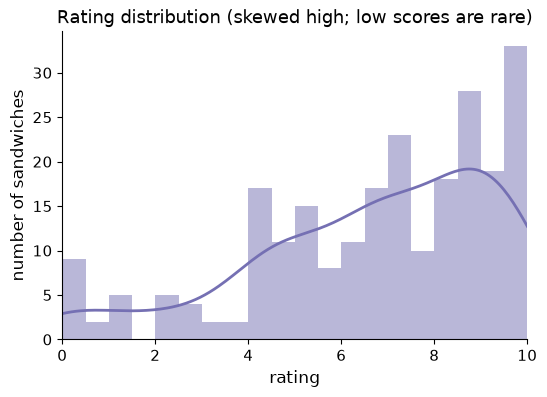

In [2]:
fig, ax = plt.subplots(figsize=(6, 4))
viz.plot_rating_distribution(ds.y, ax)
plt.show()

## 2. Ratings over time

Rating versus episode number across the show's run (non-numeric episode markers are dropped).

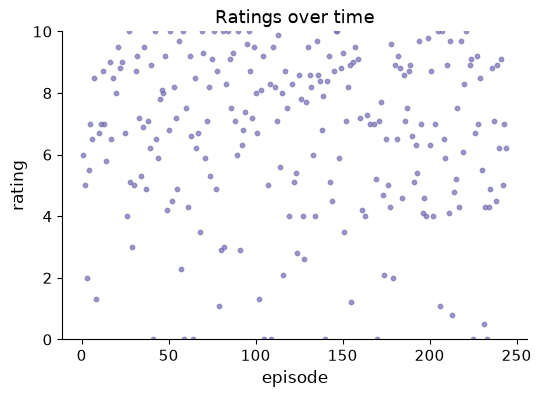

In [3]:
fig, ax = plt.subplots(figsize=(6, 4))
viz.plot_rating_timeline(ds.meta["Episode"], ds.y, ax)
plt.show()

## 3. Which ingredient values are well sampled?

The combinatorial menu is sparsely explored, so most ingredient values appear once or twice. The rating-by-ingredient
violins in section 4 need enough points per category to be legible, so they restrict to values seen at least a
handful of times (`SANDWICH_FREQ_THRESHOLD_VIOLIN`). The deli-counter search in section 7 has no such legibility
need — it just wants a bigger menu of candidate sandwiches to search over now that the model's own 2+ appearance
pruning has been removed — so it uses a looser cutoff (`SANDWICH_FREQ_THRESHOLD_DELI_SEARCH`). It can't go all the
way to "every ingredient value the model saw" (threshold 1): the candidate count is the product of the six
per-column counts, so that would enumerate ~6.5 trillion candidate sandwiches. `SANDWICH_FREQ_THRESHOLD_DELI_SEARCH`
is set to 3 -- the loosest cutoff, requiring only 3+ occurrences per ingredient value, that still stays tractable
(~15.2M candidates). One-hot encoding all of them at once would be a ~845-column dense float64 matrix (~100 GB), so
section 7 scores the menu in batches instead of in a single pass.

In [4]:
frequent = sandwiches.ingredient_value_counts(frame, SANDWICH_FREQ_THRESHOLD_VIOLIN)
search_values = sandwiches.ingredient_value_counts(
    frame, SANDWICH_FREQ_THRESHOLD_DELI_SEARCH
)
{
    "well-sampled, for the violins (section 4)": {
        col: len(values) for col, values in frequent.items()
    },
    "deli-search menu (section 7)": {
        col: len(values) for col, values in search_values.items()
    },
}

{'well-sampled, for the violins (section 4)': {'Bread': 14,
  'Main': 10,
  'Cheese': 10,
  'Roughage': 1,
  'Wild Magic': 6,
  'Sauce': 4},
 'deli-search menu (section 7)': {'Bread': 28,
  'Main': 16,
  'Cheese': 17,
  'Roughage': 5,
  'Wild Magic': 18,
  'Sauce': 21}}

## 4. Rating by ingredient (violin + swarm)

How the rating distribution shifts with each ingredient choice, restricted to the well-sampled values. A violin shows
the spread; the jittered points are the individual sandwiches.

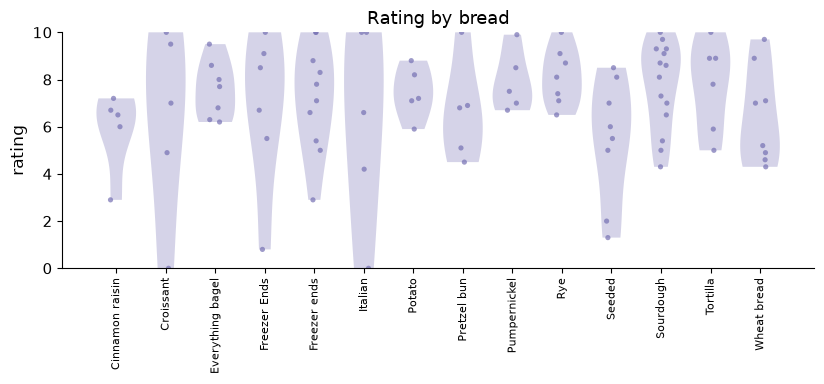

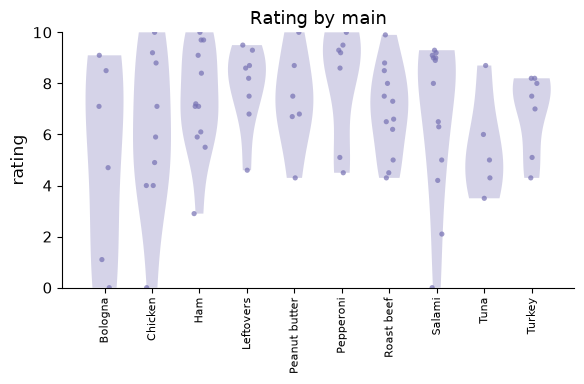

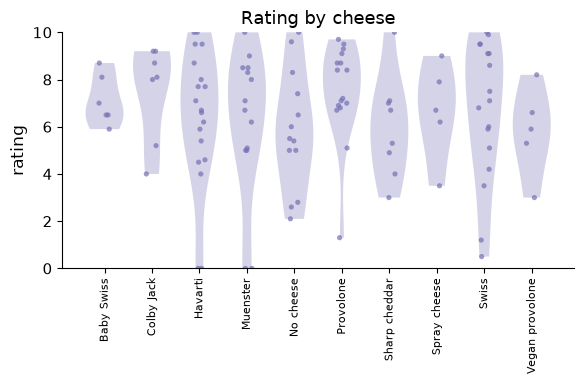

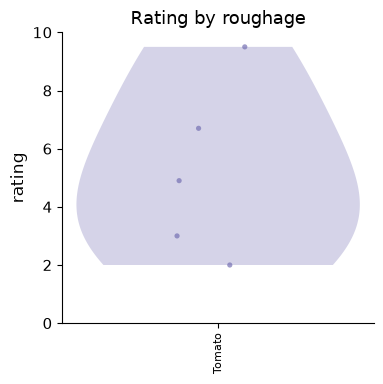

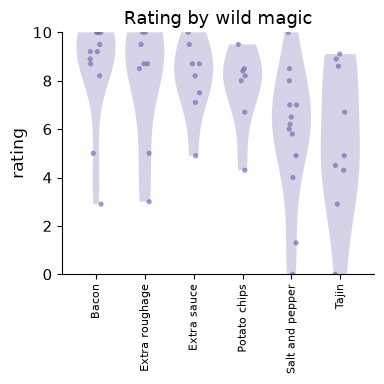

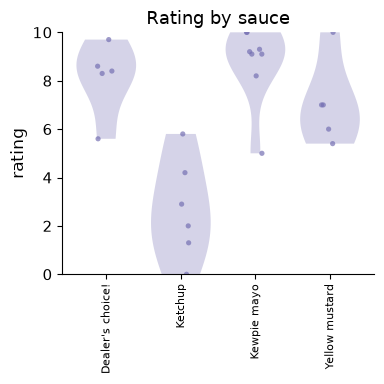

In [5]:
for col in sandwiches.INGREDIENT_COLS:
    values = frequent[col]
    if not values:
        continue
    sub = frame[frame[col].isin(values)]
    fig, ax = plt.subplots(figsize=(max(4, 0.6 * len(values)), 4))
    viz.plot_ingredient_violin(
        sub[col].to_numpy(), sub["Clean_Rating"].to_numpy(), ax, col
    )
    plt.tight_layout()
    plt.show()

## 5. Multi-hot encoding + an XGBoost rating regressor

Each ingredient value becomes its own indicator column, so a sandwich is a multi-hot row with six ones. We fit the
house XGBoost regressor on a random split — with small, shallow `SANDWICH_XGB_PARAMS`, since a few hundred sandwiches
and hundreds of one-hot columns would overfit the baseball-scale defaults. This is a genuinely hard, sparse problem,
so the held-out correlation is modest.

{'auroc': 0.658, 'auprc': 0.3, 'f1': 0.154, 'precision_at_k': 0.208, 'enrichment_factor': 1.0}


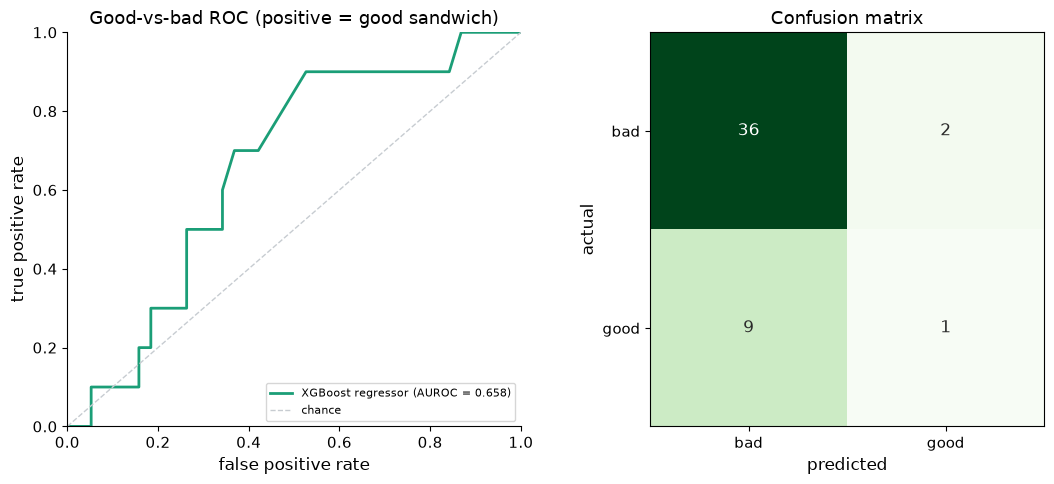

In [6]:
# The house XGBoost rating regressor (also used for the deli-counter search in
# section 7) fits the continuous 0-10 rating directly; cds only supplies the
# good-vs-bad label (SANDWICH_GOOD_RATING_THRESHOLD) used to evaluate it here,
# matching modeling.py / downselection.py's good/bad framing.
cds = sandwiches.to_classification(ds)
train_idx, test_idx = random_split(cds)
model = xgb_regressor()
model.fit(ds.X[train_idx], ds.y[train_idx])

y_test = cds.y[test_idx]
# XGBRegressor has neither predict_proba nor decision_function, so
# positive_scores falls back to predict() -- its raw continuous rating serves
# as a ranking score (see negative_ml.core.experiment). Clip to the rating
# scale and threshold at SANDWICH_GOOD_RATING_THRESHOLD to recover a hard
# good/bad prediction for the F1 metric and the confusion matrix.
y_score = np.clip(positive_scores(model, ds.X[test_idx]), 0, 10)
y_pred = (y_score >= SANDWICH_GOOD_RATING_THRESHOLD).astype(int)
print(
    {
        k: round(v, 3)
        for k, v in ev.compute_metrics(
            y_test, y_score, threshold=SANDWICH_GOOD_RATING_THRESHOLD
        ).items()
    }
)

fpr, tpr, _ = roc_curve(y_test, y_score)
fig, axes = plt.subplots(1, 2, figsize=(11, 5))
viz.plot_roc_curves(
    [("XGBoost regressor", fpr, tpr, ev.auroc(y_test, y_score))], axes[0]
)
matrix = confusion_matrix(y_test, y_pred, labels=[0, 1])
viz.plot_confusion(matrix, axes[1])
plt.tight_layout()
plt.show()

## 6. Matched pairs: near-identical sandwiches

Matched pairs are sandwiches that differ in only one or a few ingredients — near-twins whose ratings can still
diverge. Matched-pair accuracy asks whether a model fit on all the data ranks the higher-rated twin above its pair,
probing fine-grained discrimination rather than broad class separation. The menu is sparse, so the closest real pairs
differ in three of six ingredients.

In [7]:
# Matched-pair evaluation now lives in negative_ml.core.mmp (shared across all
# three domains — see scripts/mmp_experiments.py); reuse it here directly on the
# regressor trained above instead of the retired sandwiches.matched_pairs helper.
pairs = find_matched_pairs(cds.X, cds.y, max_pairs=200)
scored = score_pairs(model, cds.X, pairs)
metrics = mmp_metrics(scored)
print(
    f"matched-pair concordance = {metrics['concordance']:.3f} over {len(pairs)} pairs"
)

for _, row in scored.head(5).iterrows():
    i, j = int(row["idx_pos"]), int(row["idx_neg"])
    good = " / ".join(cds.meta.iloc[i][sandwiches.INGREDIENT_COLS])
    bad = " / ".join(cds.meta.iloc[j][sandwiches.INGREDIENT_COLS])
    print(f"  good (score={row['score_pos']:.2f}): {good}")
    print(f"  bad  (score={row['score_neg']:.2f}): {bad}\n")

matched-pair concordance = 1.000 over 5 pairs
  good (score=9.65): Pumpernickel / Roast beef / Swiss / Cucumber, tomato / Sichuan peppercorn / Barbecue sauce
  bad  (score=6.74): Cinnamon raisin / Tuna / Swiss / Lettuce / Sichuan peppercorn / Brown mustard

  good (score=9.25): Italian / Ham / Havarti / Cucumber / Bacon / Fruit jelly / jam
  bad  (score=8.53): Seeded / Bologna / Muenster / Cucumber / Extra roughage / Jelly / jam

  good (score=8.99): Gluten free white / Buffalo burger / Provolone / Tomato / Potato chips / Ponzu
  bad  (score=6.93): Pumpernickel / Peanut butter / Provolone / Tomato / Potato chips / Peanut butter

  good (score=9.24): Rye / Dark turkey, stuffing / No cheese / No roughage / Fresh mozzarella, "moistmaker" / Yellow mustard
  bad  (score=5.93): Seeded / Pastrami / No cheese / Pickles / Salt and pepper / Yellow mustard

  good (score=8.54): Waffle / Pepperoni / Grated parmesan x3 / Pickled onions, olives / Grill it! / MayoChup
  bad  (score=8.37): Waffle / Ha

## 7. Deli counter: the best and worst sandwich

Enumerate every sandwich the model can build from the wider deli-search menu (`search_values` from section 3,
ingredient values with 3+ occurrences) and ask it for the highest- and lowest-scoring one (predictions clipped to the
0-10 scale). Dropping the old 2+ appearance cutoff and switching from the violin threshold to
`SANDWICH_FREQ_THRESHOLD_DELI_SEARCH` widens this menu roughly 450x (33.6k -> 15.2M candidate sandwiches). That's too
many to one-hot encode in a single dense matrix (~100 GB), so the menu is scored in batches, keeping only the
running best/worst candidate in memory rather than the full candidate set or its scores.

searched 14,394,240 sandwiches in batches of 50,000
best score=15.43: Hawaiian bread / Pepperoni / Port wine spread / No roughage / Bacon / Dealer's choice!
worst score=-4.87: 12 grain / Bologna / No cheese / Tomato / Tajin / Ketchup


/var/folders/py/8hwb28r933z4xh4q0dw5hz2h0000gn/T/ipykernel_36705/4108665008.py:52: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


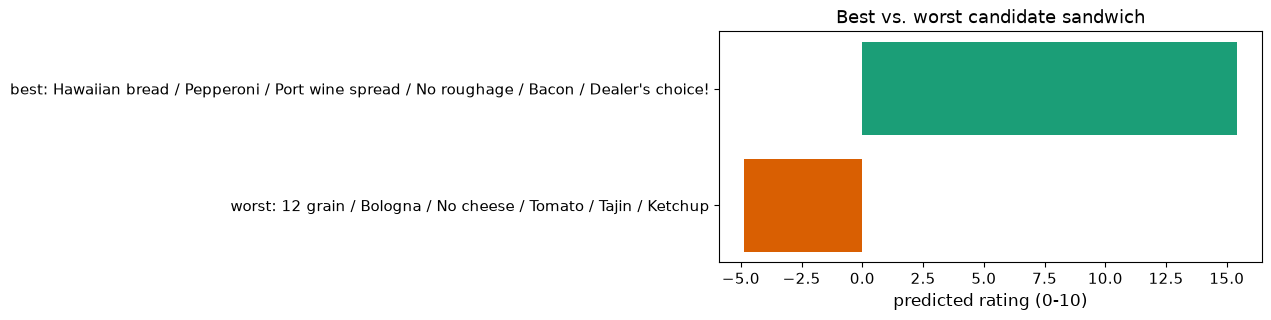

In [8]:
# The deli-counter search fits its own XGBoost rating regressor on a fresh
# (unstratified) random split of the full continuous-rating dataset, separate
# from the regressor trained in section 5 (which is evaluated against the
# good/bad label there instead). Predictions are clipped to the 0-10 rating
# scale since the regressor can extrapolate past it on candidates far from the
# training data.
reg_train_idx, _ = random_split(ds)
regressor = xgb_regressor()
regressor.fit(ds.X[reg_train_idx], ds.y[reg_train_idx])

# ~15.2M candidates is too many to one-hot encode in a single dense matrix
# (~845 feature columns -> ~100 GB), so the menu is scored batch-by-batch,
# streaming through the itertools.product iterator and keeping only the
# running best/worst score and label.
value_lists = [search_values[col] for col in sandwiches.INGREDIENT_COLS]
n_candidates = math.prod(len(values) for values in value_lists)
batch_size = 50_000

best_score, worst_score = -np.inf, np.inf
best_label, worst_label = None, None
candidate_iter = product(*value_lists)
for _ in range(0, n_candidates, batch_size):
    batch = list(islice(candidate_iter, batch_size))
    if not batch:
        break
    candidates = pd.DataFrame(batch, columns=sandwiches.INGREDIENT_COLS)
    X_cand, _ = sandwiches.encode_ingredients(
        candidates, feature_names=ds.feature_names
    )
    scores = positive_scores(regressor, X_cand)

    i_max, i_min = int(scores.argmax()), int(scores.argmin())
    if scores[i_max] > best_score:
        best_score = scores[i_max]
        best_label = " / ".join(candidates.iloc[i_max])
    if scores[i_min] < worst_score:
        worst_score = scores[i_min]
        worst_label = " / ".join(candidates.iloc[i_min])

print(f"searched {n_candidates:,} sandwiches in batches of {batch_size:,}")
print(f"best score={best_score:.2f}: {best_label}")
print(f"worst score={worst_score:.2f}: {worst_label}")

fig, ax = plt.subplots(figsize=(7, 3))
ax.barh(
    [f"worst: {worst_label}", f"best: {best_label}"],
    [worst_score, best_score],
    color=[dark2(1), dark2(0)],
)
ax.set_xlabel("predicted rating (0-10)")
ax.set_title("Best vs. worst candidate sandwich")
plt.tight_layout()
plt.show()